# Paper: LSTTN: A Long-Short Term Transformer-based Spatio-temporal Neural Network for Traffic Flow Forecasting 
- **Mục đích:** Xây dựng một mô hình để dự đoán lưu lượng giao thông trong tương lai chính xác hơn, bằng cách học được cả thông tin ngắn hạn và dài hạn của giao thông. So sánh xem LSTTN tốt hơn so với các phương pháp khác như nào.
- **Input:** 4 bộ DL với `METR-LA` và `PEMS-BAY` là dữ liệu về tốc độ theo thời gian, `PEMS04` và `PEMS08` là dữ liệu với csv là các node giao thông, khoảng cách và npz là flow, occupancy (mức độ đường bị xe chiếm dụng), speed. 
- **Output:** Trong khuôn khổ bài tập thì sẽ dùng một bảng là `METR-LA` để train model và so sánh với các thông số của LSTTN trong paper. Paper cũng so sánh LSTTN với nhiều baseline như DCRNN, STGCN, ASTGCN, GMAN… và chứng minh LSTTN vượt trội hơn về RMSE, MAE, MAPE.  

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.impute import KNNImputer
from sklearn.metrics import  mean_absolute_error, root_mean_squared_error, r2_score, mean_absolute_percentage_error
from sklearn.linear_model import LinearRegression

from statsmodels.tsa.stattools import adfuller

In [47]:
df = pd.read_csv("D:/Project_Github/predictiveDA-weekly-assigment/paper/dataset/processed_data/METR-LA.csv")
df.head()

,Unnamed: 0,773869,767541,767542,717447,717446,717445,773062,767620,737529,...,772167,769372,774204,769806,717590,717592,717595,772168,718141,769373
0,1330560000000000000,64.375000,67.625000,67.125000,61.500000,66.875000,68.750000,65.125,67.125,59.625000,...,45.625000,65.500,64.500000,66.428571,66.875,59.375000,69.000000,59.250000,69.000000,61.875
1,1330560300000000000,62.666667,68.555556,65.444444,62.444444,64.444444,68.111111,65.000,65.000,57.444444,...,50.666667,69.875,66.666667,58.555556,62.000,61.111111,64.444444,55.888889,68.444444,62.875
2,1330560600000000000,64.000000,63.750000,60.000000,59.000000,66.500000,66.250000,64.500,64.250,63.875000,...,44.125000,69.000,56.500000,59.250000,68.125,62.500000,65.625000,61.375000,69.857143,62.000
3,1330560900000000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000,0.000,0.000000,...,0.000000,0.000,0.000000,0.000000,0.000,0.000000,0.000000,0.000000,0.000000,0.000
4,1330561200000000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000,0.000,0.000000,...,0.000000,0.000,0.000000,0.000000,0.000,0.000000,0.000000,0.000000,0.000000,0.000


- Cột đầu tiên là thời điểm với đơn vị Unix timestamp nanosecond. Cần phải chuyển về datetime để dễ đọc.
- Các cột còn lại là tốc độ tại các điểm đo, với số là ID của các điểm, giá trị 0 chính là các giá trị cần xử lí.
- Không cần chọn lựa đặc trưng vì các điểm ứng với các điểm đo và có giá trị ngang nhau, không tương quan bởi vì không biết được các cột ứng với tọa độ bao nhiêu để có thể đo được khoảng cách hay xét xa gần. Như vậy, mỗi sensor ứng với một bài toán dự đoán con nên với khuôn khổ bài tập sẽ trích ra cột Time và dữ liệu tại điểm đo có ID = 773869 để huấn luyện dữ liệu trước. 

In [48]:
df = df.rename(columns={'Unnamed: 0': 'time'})

df["time"] = pd.to_datetime(df['time'], unit='ns')

df.head()

,time,773869,767541,767542,717447,717446,717445,773062,767620,737529,...,772167,769372,774204,769806,717590,717592,717595,772168,718141,769373
0,2012-03-01 00:00:00,64.375000,67.625000,67.125000,61.500000,66.875000,68.750000,65.125,67.125,59.625000,...,45.625000,65.500,64.500000,66.428571,66.875,59.375000,69.000000,59.250000,69.000000,61.875
1,2012-03-01 00:05:00,62.666667,68.555556,65.444444,62.444444,64.444444,68.111111,65.000,65.000,57.444444,...,50.666667,69.875,66.666667,58.555556,62.000,61.111111,64.444444,55.888889,68.444444,62.875
2,2012-03-01 00:10:00,64.000000,63.750000,60.000000,59.000000,66.500000,66.250000,64.500,64.250,63.875000,...,44.125000,69.000,56.500000,59.250000,68.125,62.500000,65.625000,61.375000,69.857143,62.000
3,2012-03-01 00:15:00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000,0.000,0.000000,...,0.000000,0.000,0.000000,0.000000,0.000,0.000000,0.000000,0.000000,0.000000,0.000
4,2012-03-01 00:20:00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000,0.000,0.000000,...,0.000000,0.000,0.000000,0.000000,0.000,0.000000,0.000000,0.000000,0.000000,0.000


In [49]:
df.shape

(34272, 208)

In [50]:
print({df["time"].min()})
print({df["time"].max()})

{Timestamp('2012-03-01 00:00:00')}
{Timestamp('2012-06-27 23:55:00')}


Dữ liệu được thu thập tự động, khoảng 5 phút tất cả các điểm đo sẽ đo tốc độ một lần, trải dài từ 1/3/2012 đến 27/6/2012.


In [51]:
missing_cols = df.isna().sum()
print(missing_cols[missing_cols != 0])

Series([], dtype: int64)


Không có giá trị null

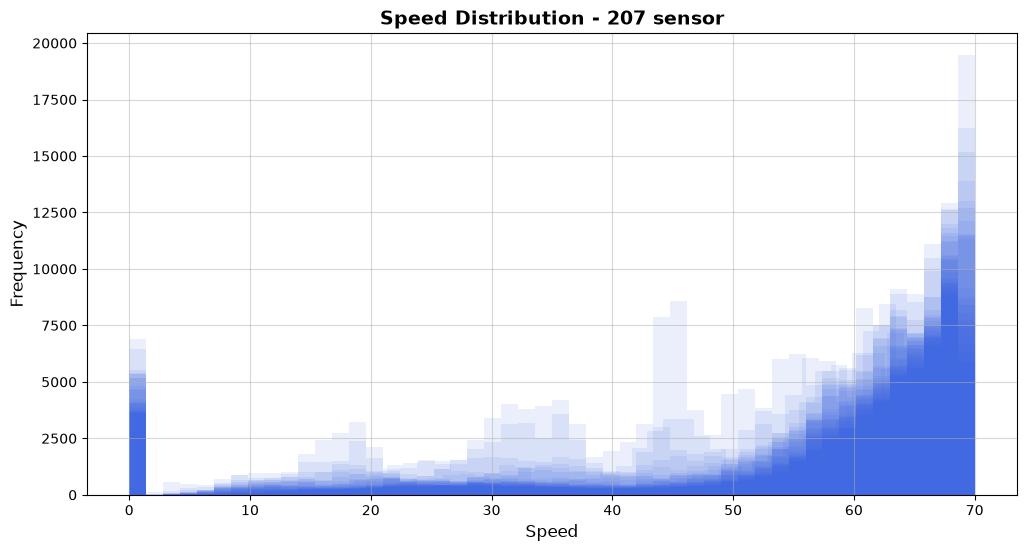

In [52]:
sensor_cols = df.columns.drop('time', errors='ignore')

plt.figure(figsize=(12, 6))

for sensor in sensor_cols:
    plt.hist(df[sensor].dropna(), bins=50, alpha=0.1, color='royalblue', edgecolor=None)

plt.title("Speed Distribution - 207 sensor", fontsize=14, fontweight='bold')
plt.xlabel("Speed", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.grid(True, alpha=0.5)

plt.show()

In [53]:
# Số lượng các giá trị bằng 0
print((df == 0).sum().sum())

575302


Dữ liệu phân bố đồng đều từ 0 đến 70. 

Tuy nhiên với dữ liệu tốc độ bằng 0 (outlier) cần lưu ý:  
- Có những hàng mà tất cả các sensor đều bằng 0. Có thể là do mất điện hoặc là mất tín hiệu toàn hệ thống đo. 
- Nếu không thì chuỗi 0 sẽ xuất hiện với các chuỗi khác nhau. Ta phải chú ý xem đó là lỗi hay là tắc.

BTVN 4 đã làm bộ dữ liệu này nhưng xử lí 0 không được tốt nên mô hình ra rất kém, kết quả sai rõ rệt ở các dữ liệu bằng 0. 

**Hướng xử lí:**
- Nếu chuỗi 0 dài thì sẽ điền dựa theo quy luật ngày, tuần. 
- Nếu chuỗi 0 ngắn mà tốc độ ở 2 phía là giảm dần (VD 60 40 20 0 20 40 60) thì được xếp vào là tắc và được giữ nguyên là 0.
- Nếu chuỗi 0 ngắn mà giảm đột ngột (VD 60 0 0 40) thì được xếp là lỗi dữ liệu, chuyển về NaN và fill bằng ffill, interpolation (nội suy), median và KNN tùy theo cái nào là tốt nhất.

# BÀI TOÁN CON VỚI SENSOR CÓ ID = 773869

In [54]:
df_new = df[['time', '773869']].copy()
df_new.shape

(34272, 2)

In [55]:
df_new.head()

,time,773869
0,2012-03-01 00:00:00,64.375000
1,2012-03-01 00:05:00,62.666667
2,2012-03-01 00:10:00,64.000000
3,2012-03-01 00:15:00,0.000000
4,2012-03-01 00:20:00,0.000000


In [56]:
print({df_new["time"].min()})
print({df_new["time"].max()})

{Timestamp('2012-03-01 00:00:00')}
{Timestamp('2012-06-27 23:55:00')}


In [58]:
# Số lượng các giá trị bằng 0
print((df_new == 0).sum().sum())

3843


## 1. Xử lí giá trị 0

In [ ]:
# Thống kê độ dài các chuỗi 0
def count_and_summarize_zero_runs(series):
    is_zero = series.eq(0)
    groups = is_zero.ne(is_zero.shift()).cumsum()
    zero_runs = is_zero.groupby(groups).agg(lambda x: len(x) if x.iloc[0] else 0)
    zero_runs = zero_runs[zero_runs > 0]
    summary = zero_runs.value_counts().sort_index()
    return summary

result = count_and_summarize_zero_runs(df_new['773869'])

for length, count in result.items():
    print(f"{length} - {count} chuỗi")

1 - 39 chuỗi
2 - 31 chuỗi
3 - 11 chuỗi
4 - 2 chuỗi
5 - 3 chuỗi
6 - 3 chuỗi
7 - 3 chuỗi
8 - 5 chuỗi
9 - 6 chuỗi
10 - 2 chuỗi
12 - 3 chuỗi
13 - 1 chuỗi
16 - 3 chuỗi
17 - 1 chuỗi
18 - 3 chuỗi
19 - 1 chuỗi
20 - 2 chuỗi
23 - 1 chuỗi
27 - 2 chuỗi
30 - 1 chuỗi
31 - 1 chuỗi
33 - 1 chuỗi
35 - 1 chuỗi
44 - 1 chuỗi
50 - 1 chuỗi
71 - 1 chuỗi
72 - 1 chuỗi
75 - 1 chuỗi
99 - 1 chuỗi
107 - 1 chuỗi
118 - 1 chuỗi
121 - 1 chuỗi
127 - 1 chuỗi
156 - 1 chuỗi
166 - 2 chuỗi
229 - 1 chuỗi
381 - 1 chuỗi
1118 - 1 chuỗi


Ta thấy từ chuỗi có độ dài 4 trở đi thì số lượng xuất hiện không nhiều nên ta sẽ coi như chuỗi 4 là một chuỗi dài để tính toán. 

### 1.1. Chuỗi 0 ngắn, giảm dần

In [61]:
# Lọc các chuỗi 0 dài và ngắn với threshold là 4
def filter_zeros_by_trend(s, threshold_long=4, lookback=3):
    """
    Xử lý chuỗi 0 ngắn (< threshold_long):
    - Kiểm tra xem các giá trị trước đó có đang giảm dần (decreasing trend) hay không.
    - Nếu trước đó giảm dần (vd: 60 -> 40 -> 20 -> 0) -> Tắc thật -> Giữ nguyên 0.
    - Nếu rớt đột ngột từ cao xuống 0 (vd: 60 -> 0) -> Lỗi cảm biến -> Chuyển thành NaN để điền khuyết.
    """
    s_clean = s.copy()
    is_zero = (s_clean == 0)
    zero_groups = (is_zero != is_zero.shift()).cumsum()
    
    for group_id, group_data in s_clean.groupby(zero_groups):
        if group_data.iloc[0] == 0:
            length = len(group_data)
            start_idx = group_data.index[0]
            end_idx = group_data.index[-1]
            
            # Nếu là chuỗi 0 dài (>= 4)
            if length >= threshold_long:
                continue
                
            # Lấy các giá trị ngay trước chuỗi 0 (3 mốc trước đó)
            if start_idx >= lookback:
                pre_vals = s_clean.iloc[start_idx - lookback : start_idx].values
            else:
                pre_vals = s_clean.iloc[0:start_idx].values
                
            # Kiểm tra xu hướng giảm dần trước đó
            # Điều kiện giảm: Điểm ngay sát số 0 phải nhỏ hơn điểm đứng trước nó, 
            # HOẶC giá trị ngay sát số 0 phải ở mức thấp (<= 35)
            has_decreasing_trend = False
            if len(pre_vals) >= 2:
                if (pre_vals[-1] < pre_vals[-2]) or (pre_vals[-1] <= 35):
                    has_decreasing_trend = True
            elif len(pre_vals) == 1:
                if pre_vals[0] <= 35:
                    has_decreasing_trend = True
                    
            if has_decreasing_trend:
                # Tắc thật (có quá trình giảm dần) -> Giữ nguyên số 0
                pass
            else:
                # Lỗi đột ngột (không có giảm dần) -> Chuyển thành NaN
                s_clean.loc[start_idx:end_idx] = np.nan
                
    return s_clean

In [66]:
df1 = df_new.copy()
df1['773869'] = filter_zeros_by_trend(df1['773869'], threshold_long=4, lookback=3)
print("Đã phân loại")

Đã phân loại


In [67]:
df1.isna().sum()

time       0
773869    79
dtype: int64

## 1.2. Chuỗi 0 ngắn, giảm đột ngột 
Chuỗi 0 ngắn, giảm đột ngột được chuyển thành NaN. Bài toán trở thành xử lí giá trị thiếu.  
4 phương pháp ffill, interpolation (nội suy), median và KNN  
Sử dụng Masked Subseries Transformer giống như bài toán để đánh giá xem phương pháp nào thì ổn nhất. 

In [68]:
df2_test = df1.copy()

np.random.seed(42)
mask_observed = df2_test.notna()

# Chỉ lấy các ô đang có giá trị
observed_positions = np.where(mask_observed.values)

# Giả lập 3% giá trị đang có thành missing
n_mask = int(len(observed_positions[0]) * 0.03)

selected = np.random.choice(
    len(observed_positions[0]),
    size=n_mask,
    replace=False
)

rows = observed_positions[0][selected]
cols = observed_positions[1][selected]


# Lưu lại giá trị thật trước khi che
true_values = df2_test.values[rows, cols].copy()

# Tạo missing giả lập
df2_masked = df2_test.copy()
for r, c in zip(rows, cols):
  df2_masked.iloc[r, c] = np.nan

print("Tổng số giá trị: ", df1.shape[0] * df1.shape[1])
print("Số giá trị bị che:", n_mask)

Tổng số giá trị:  68544
Số giá trị bị che: 2053


In [69]:
# FFill
df2_ffill = df2_masked.ffill()

# Linear Interpolation
df2_linear = df2_masked.interpolate(
    method="linear",
    limit_direction="both"
)

# Median
df2_median = df2_masked.copy()

for col in df2_median.columns:
    median_value = df2_median[col].median()
    df2_median[col] = df2_median[col].fillna(median_value)

In [247]:
'''
# KNN (với số neighbors là 3 4 5 6 7)
knn3_imputer = KNNImputer(n_neighbors=3)
df4_knn3 = pd.DataFrame(
    knn3_imputer.fit_transform(df4_masked),
    columns=df4_masked.columns,
    index=df4_masked.index
)

knn4_imputer = KNNImputer(n_neighbors=4)
df4_knn4 = pd.DataFrame(
    knn4_imputer.fit_transform(df4_masked),
    columns=df4_masked.columns,
    index=df4_masked.index
)

knn5_imputer = KNNImputer(n_neighbors=5)
df4_knn5 = pd.DataFrame(
    knn5_imputer.fit_transform(df4_masked),
    columns=df4_masked.columns,
    index=df4_masked.index
)

knn6_imputer = KNNImputer(n_neighbors=6)
df4_knn6 = pd.DataFrame(
    knn6_imputer.fit_transform(df4_masked),
    columns=df4_masked.columns,
    index=df4_masked.index
)

knn7_imputer = KNNImputer(n_neighbors=7)
df4_knn7 = pd.DataFrame(
    knn7_imputer.fit_transform(df4_masked),
    columns=df4_masked.columns,
    index=df4_masked.index
)'''
# Đã chạy thử và thấy kết quả không tốt bằng các cách fill khác nên bỏ

'\n# KNN (với số neighbors là 3 4 5 6 7)\nknn3_imputer = KNNImputer(n_neighbors=3)\ndf4_knn3 = pd.DataFrame(\n    knn3_imputer.fit_transform(df4_masked),\n    columns=df4_masked.columns,\n    index=df4_masked.index\n)\n\nknn4_imputer = KNNImputer(n_neighbors=4)\ndf4_knn4 = pd.DataFrame(\n    knn4_imputer.fit_transform(df4_masked),\n    columns=df4_masked.columns,\n    index=df4_masked.index\n)\n\nknn5_imputer = KNNImputer(n_neighbors=5)\ndf4_knn5 = pd.DataFrame(\n    knn5_imputer.fit_transform(df4_masked),\n    columns=df4_masked.columns,\n    index=df4_masked.index\n)\n\nknn6_imputer = KNNImputer(n_neighbors=6)\ndf4_knn6 = pd.DataFrame(\n    knn6_imputer.fit_transform(df4_masked),\n    columns=df4_masked.columns,\n    index=df4_masked.index\n)\n\nknn7_imputer = KNNImputer(n_neighbors=7)\ndf4_knn7 = pd.DataFrame(\n    knn7_imputer.fit_transform(df4_masked),\n    columns=df4_masked.columns,\n    index=df4_masked.index\n)'

In [70]:
# Hàm tính MAE và RMSE
def evaluate_imputation(df_imputed, rows, cols, true_values):

    predicted_values = df_imputed.values[rows, cols]

    valid = ~np.isnan(predicted_values)

    true = true_values[valid]
    predicted = predicted_values[valid]

    mae = mean_absolute_error(true, predicted)
    rmse = np.sqrt(root_mean_squared_error(true, predicted))

    return mae, rmse

In [73]:
print(df1.dtypes) # Kiểm tra kiểu dữ liệu các cột

time      datetime64[ns]
773869           float64
dtype: object


In [74]:
# Đánh giá các phương pháp
results = []

for method, df_imputed in {
    "FFill": df2_ffill,
    "Linear": df2_linear,
    "Median": df2_median
}.items():

    mae, rmse = evaluate_imputation(
        df_imputed,
        rows,
        cols,
        true_values
    )

    results.append({
        "Method": method,
        "MAE": mae,
        "RMSE": rmse
    })


results_df = pd.DataFrame(results)

print(results_df)

TypeError: ufunc 'isnan' not supported for the input types, and the inputs could not be safely coerced to any supported types according to the casting rule ''safe''

Dựa vào MAE và RMSE sau khi áp dụng Mask thì ta sử dụng Nội suy tuyến tính (Linear) để fill dữ liệu missing

In [250]:
# Áp dụng vào dữ liệu thật
df2 = df1.interpolate(
    method="linear",
    limit_direction="both"
)

print("Số lượng NaN trước khi fill:", df1.isna().sum().sum())
print("Số lượng NaN sau khi fill:", df2.isna().sum().sum())

Số lượng NaN trước khi fill: 547852
Số lượng NaN sau khi fill: 0


### Xử lí outlier

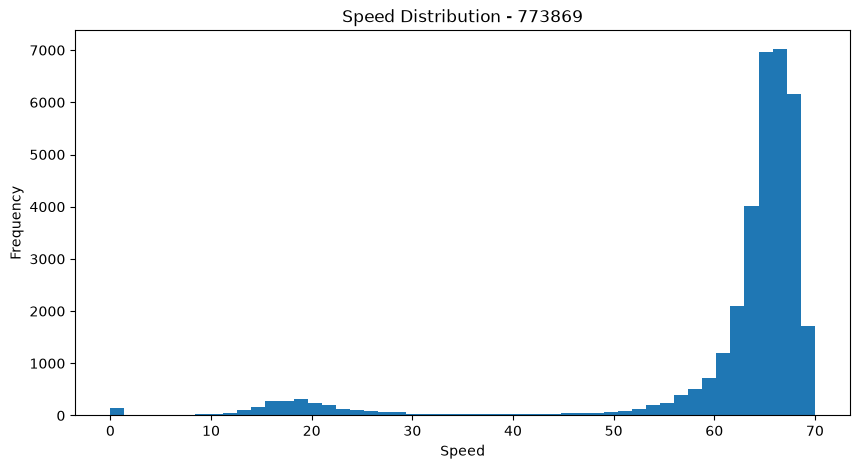

Số lượng giá trị bằng 0: 142


In [275]:
df3 = df2.copy()

# Vẽ Histogram
sensor = df3.columns[0]

plt.figure(figsize=(10, 5))
plt.hist(df3[sensor].dropna(), bins=50)

plt.title(f"Speed Distribution - {sensor}")
plt.xlabel("Speed")
plt.ylabel("Frequency")

plt.show()

zero_count = (df3[sensor] == 0).sum()

print(f"Số lượng giá trị bằng 0: {zero_count}")

Dữ liệu bình thường so với giao thông đô thị, tốc độ bằng 0 là có thể do tắc đường chật cứng không đi được

## 3. Chia train/test
Vì là dữ liệu time series nên không thể chia random 70/30 được mà sẽ train ở quá khứ và test ở tương lai với X là vector gồm các giá trị quá khứ, y là giá trị hiện tại hoặc tương lai.  
Bộ dữ liệu METR-LA không chia rõ thành X, y như các tập dữ liệu khác nên sẽ sử dụng cách chia cửa sổ trượt để có thể làm 1 lần học của model. Tức là lấy 11 thời điểm của 207 điểm đo để dự đoán cho thời điểm thứ 12.

In [252]:
df4 = df3.copy()

input_len = 12

X = []
y = []

for i in range(input_len, len(df4)):
    # 12 thời điểm × 207 sensor
    X.append(
        df4.iloc[i-input_len:i].values.flatten()
    )

    # 207 sensor ở thời điểm hiện tại
    y.append(
        df4.iloc[i].values
    )

X = np.array(X)
y = np.array(y)

print("X:", X.shape)
print("y:", y.shape)

X: (34260, 2484)
y: (34260, 207)


In [253]:
# 2484 = 12 x 207

# Chia train/test - vì mục đích cũng để so sánh với paper nên chỉ train ở 70% và test trên 10%
train_end = int(len(X) * 0.7)
val_end = int(len(X) * 0.9)

X_train = X[:train_end]
X_test = X[val_end:]

y_train = y[:train_end]
y_test = y[val_end:]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (23982, 2484)
X_test: (3426, 2484)
y_train: (23982, 207)
y_test: (3426, 207)


# 4. Model fitting
Sử dụng các phương pháp Regression để xử lí vì output cần một giá trị liên tục thay vì các nhãn rời rạc như Classification

### Linear Regresssion

In [254]:
slr = LinearRegression()

# Huấn luyện mô hình trên tập train
slr.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](207, 2484)","[[-0.02,-0.01,-0.01,...,-0. , 0. , 0.01], [-0.01,-0.01,-0.01,..., 0.01, 0.01, 0. ], [-0.01, 0. ,-0.02,..., 0. ,-0. ,-0. ], ..., [-0.02, 0. ,-0.02,..., 0.47, 0. , 0.02], [-0.02, 0. , 0.01,..., 0. , 0.57, 0. ], [-0.02, 0.02,-0.01,..., 0.01,-0. , 0.8 ]]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](207,)","[29.12,29.27,28.98,...,27.11,28.81,27.13]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2484
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2484)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](2484,)","[51495.49,32833.52,22187.48,..., 142.8 , 142.51, 140.37]"


In [255]:
# LinearRegression y=αx+β
# 𝛽
slr.intercept_

array([29.11523819, 29.26986384, 28.98353382, 24.58524599, 22.53430753,
       27.32385676, 22.75728373, 28.61072892, 26.36788579, 26.68947943,
       28.01593078, 27.95805407, 16.2419943 , 28.93731936, 21.20434646,
       23.71860154, 13.26221388, 25.83577502, 23.84328653, 25.48239873,
       28.91506836, 25.55501366, 22.46348589, 21.86529537, 31.90915544,
       23.40599269, 18.74775074, 28.91742519, 28.94321885, 20.52872135,
       26.22221998, 32.13893834, 29.04220236, 28.57937727, 29.05267429,
       28.08709607, 28.32702045, 24.62987857, 19.60762165, 25.18919365,
       26.96702582, 25.64439407, 26.49640202, 24.61010503, 31.76016522,
       30.92666077, 27.27730352, 23.91894922, 23.05262723, 23.73421021,
       26.15784099, 20.04333368, 24.62328069, 24.03199946, 24.59172316,
       27.27428166, 14.07295382, 24.88759722, 25.64037582, 27.84567763,
       25.50293925, 22.61231441, 26.74856659, 28.63664725, 28.79865272,
       31.13603328, 28.86684109, 30.28960991, 29.42122765, 27.72

In [256]:
# 𝛼
# we choosed two features, so for each of them we have one
slr.coef_

array([[-1.65523591e-02, -5.88496954e-03, -9.85457784e-03, ...,
        -1.29269699e-03,  4.73486067e-03,  1.23429303e-02],
       [-8.54547032e-03, -6.54502257e-03, -5.13196289e-03, ...,
         8.67313482e-03,  1.00063045e-02,  2.97410361e-03],
       [-6.27790666e-03,  2.34927644e-03, -1.65986208e-02, ...,
         3.72122998e-03, -1.54490159e-03, -1.34030153e-03],
       ...,
       [-1.55182652e-02,  2.14004711e-03, -1.54903112e-02, ...,
         4.68804637e-01,  2.42987698e-03,  1.82201652e-02],
       [-2.07008400e-02,  4.76808738e-03,  5.17480920e-03, ...,
         3.91886316e-03,  5.74653528e-01,  6.18832113e-04],
       [-1.82969011e-02,  1.69129242e-02, -1.34012005e-02, ...,
         6.86916467e-03, -7.36458305e-04,  7.97202225e-01]],
      shape=(207, 2484))

In [257]:
# Đánh giá mô hình
y_pred_train = slr.predict(X_train)
y_pred_test = slr.predict(X_test)

# Đánh giá trên Train Data
print('Train evaluation:')
print('R^2:', r2_score(y_train, y_pred_train))
print('MAE:', mean_absolute_error(y_train, y_pred_train))
print('RMSE:', root_mean_squared_error(y_train, y_pred_train))
print('MAPE:', mean_absolute_percentage_error(y_train, y_pred_train) * 100)

# Đánh giá trên Test Data
print('\nTest evaluation:')
print('R^2:', r2_score(y_test, y_pred_test))
print('MAE:', mean_absolute_error(y_test, y_pred_test))
print('RMSE:', root_mean_squared_error(y_test, y_pred_test))
print('MAPE:', mean_absolute_percentage_error(y_test, y_pred_test) * 100)


Train evaluation:
R^2: 0.7528366552596901
MAE: 2.685762220500435
RMSE: 4.618933868903813
MAPE: 7.170256643017929e+16

Test evaluation:
R^2: 0.6109110130701836
MAE: 3.149601131643014
RMSE: 5.307499867254904
MAPE: 6.722472217544864e+16


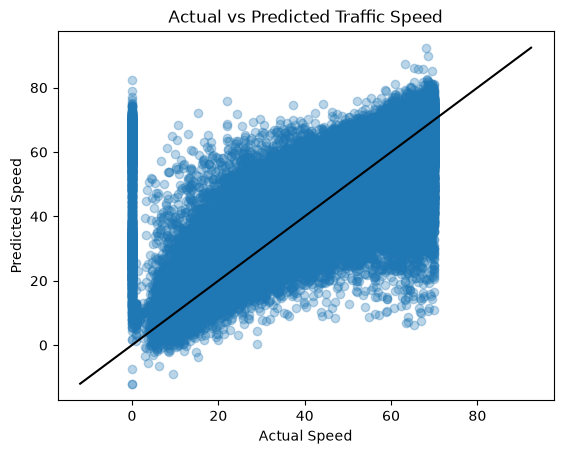

In [273]:
plt.scatter(
    y_test.flatten(),
    y_pred_test.flatten(),
    alpha=0.3
)

min_val = min(y_test.min(), y_pred_test.min())
max_val = max(y_test.max(), y_pred_test.max())
plt.plot([min_val, max_val], [min_val, max_val], color='black', linewidth=1.5, label='Ideal (y=x)')

plt.xlabel("Actual Speed")
plt.ylabel("Predicted Speed")
plt.title("Actual vs Predicted Traffic Speed")
plt.show()

Mô hình dự đoán sai số còn khá là lớn vì vẫn phân tán lệch so với đường thẳng.

Ở khu vực trục X bằng khoảng 0, có một cột dữ liệu dày đặc kéo dài từ giá trị dự đoán rất thấp (dưới 0) cho đến rất cao (gần 80). Điều này cho thấy mô hình gặp vấn đề lớn khi dự đoán các trường hợp tốc độ thực tế bằng 0 (ví dụ: tắc đường nghiêm trọng, dừng đèn đỏ). Mô hình thường đoán nhầm thành các mức tốc độ cao hơn rất nhiều.

<Figure size 600x400 with 0 Axes>

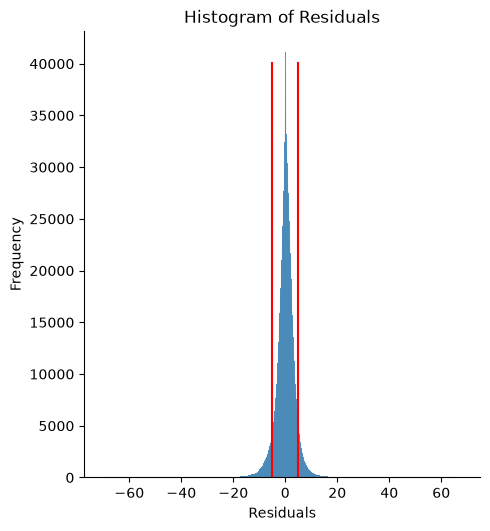

In [259]:
plt.figure(figsize=(6,4), dpi=100)

sns.displot(y_train.flatten() - y_pred_train.flatten())

plt.title('Histogram of Residuals')
plt.xlabel('Residuals')
plt.ylabel('Frequency')

plt.axvline(-5, color='red', ymax=0.929)
plt.axvline(5, color='red', ymax=0.929)

plt.show()

- Phần lớn dự đoán khá sát với giá trị thực tế khi tập trung quanh 0
- Mô hình đối xứng, không thiên lệch
- Hầu hết đều nằm trong khoảng +- 5 nhưng lại trải dài từ -60 đến 60. Thể hiện vẫn có sai số lớn.
- Mô hình tuyến tính đơn thuần vẫn chưa xử lí tốt được sự biến thiên phức tạp của giao thông.

### Test trên mốc 3 (15 phút), 6 (30 phút), 24 (2 giờ)

#### 3 (15 phút)

In [260]:
df4_3 = df3.copy()

input_len = 3

X3 = []
y3 = []

for i in range(input_len, len(df4_3)):
    # 3 thời điểm × 207 sensor
    X3.append(
        df4_3.iloc[i-input_len:i].values.flatten()
    )

    # 207 sensor ở thời điểm hiện tại
    y3.append(
        df4_3.iloc[i].values
    )

X3 = np.array(X3)
y3 = np.array(y3)

print("X:", X3.shape)
print("y:", y3.shape)

X: (34269, 621)
y: (34269, 207)


In [261]:
# Chia train/test
train_end3 = int(len(X3) * 0.7)
val_end3 = int(len(X3) * 0.9)

X_train3 = X3[:train_end3]
X_test3 = X3[val_end3:]

y_train3 = y3[:train_end3]
y_test3 = y3[val_end3:]

print("X_train3:", X_train3.shape)
print("X_test3:", X_test3.shape)
print("y_train3:", y_train3.shape)
print("y_test3:", y_test3.shape)

X_train3: (23988, 621)
X_test3: (3427, 621)
y_train3: (23988, 207)
y_test3: (3427, 207)


In [262]:
slr.fit(X_train3, y_train3)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](207, 621)","[[ 0.05,-0.01,-0.01,...,-0.01, 0. , 0.01], [ 0.02, 0.09,-0.02,...,-0.01, 0.01,-0.01], [ 0.01, 0. ,-0.01,...,-0.02,-0. ,-0.01], ..., [ 0.01, 0.01,-0.01,..., 0.49, 0. , 0.01], [-0. ,-0.01, 0.01,...,-0. , 0.58,-0.01], [ 0. ,-0.02,-0.02,..., 0.01,-0. , 0.8 ]]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](207,)","[34.35,37.64,37.76,...,33.19,36. ,32.81]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,621
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(621)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](621,)","[26697.43,16651.92,11833.85,..., 223.36, 179.42, 155.86]"


In [263]:
# Đánh giá mô hình
y_pred_train3 = slr.predict(X_train3)
y_pred_test3 = slr.predict(X_test3)

# Đánh giá trên Train Data
print('Train evaluation 3:')
print('R^2:', r2_score(y_train3, y_pred_train3))
print('MAE:', mean_absolute_error(y_train3, y_pred_train3))
print('RMSE:', root_mean_squared_error(y_train3, y_pred_train3))
print('MAPE:', mean_absolute_percentage_error(y_train3, y_pred_train3) * 100)

# Đánh giá trên Test Data
print('\nTest evaluation 3:')
print('R^2:', r2_score(y_test3, y_pred_test3))
print('MAE:', mean_absolute_error(y_test3, y_pred_test3))
print('RMSE:', root_mean_squared_error(y_test3, y_pred_test3))
print('MAPE:', mean_absolute_percentage_error(y_test3, y_pred_test3) * 100)

Train evaluation 3:
R^2: 0.7172667257713125
MAE: 2.662358465823083
RMSE: 4.948060269909984
MAPE: 8.260833254113237e+16

Test evaluation 3:
R^2: 0.6465694990965202
MAE: 2.8283587090935316
RMSE: 5.081547674817815
MAPE: 6.710576668962565e+16


### 6 (30 phút)

In [264]:
df4_6 = df3.copy()

input_len = 6

X6 = []
y6 = []

for i in range(input_len, len(df4_6)):
    # 6 thời điểm × 207 sensor
    X6.append(
        df4_6.iloc[i-input_len:i].values.flatten()
    )

    # 207 sensor ở thời điểm hiện tại
    y6.append(
        df4_6.iloc[i].values
    )

X6 = np.array(X6)
y6 = np.array(y6)

print("X:", X6.shape)
print("y:", y6.shape)

X: (34266, 1242)
y: (34266, 207)


In [265]:
# Chia train/test
train_end6 = int(len(X6) * 0.7)
val_end6 = int(len(X6) * 0.9)

X_train6 = X6[:train_end6]
X_test6 = X6[val_end6:]

y_train6 = y6[:train_end6]
y_test6 = y6[val_end6:]

print("X_train6:", X_train6.shape)
print("X_test6:", X_test6.shape)
print("y_train6:", y_train6.shape)
print("y_test6:", y_test6.shape)

X_train6: (23986, 1242)
X_test6: (3427, 1242)
y_train6: (23986, 207)
y_test6: (3427, 207)


In [266]:
slr.fit(X_train6, y_train6)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](207, 1242)","[[-0.01, 0. ,-0. ,...,-0.01, 0. , 0.01], [ 0. , 0.01,-0.01,..., 0. , 0.01,-0. ], [ 0. , 0.01,-0. ,...,-0.01,-0. ,-0. ], ..., [-0. ,-0.02,-0.01,..., 0.47,-0. , 0.01], [-0.01,-0.01, 0. ,..., 0. , 0.58,-0.01], [-0.01,-0.02, 0.02,..., 0.01,-0. , 0.8 ]]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](207,)","[30.54,31.89,31.59,...,28.85,31.97,28.52]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1242
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1242)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1242,)","[37076.12,23453.95,16186.83,..., 161.19, 152.33, 148.64]"


In [267]:
# Đánh giá mô hình
y_pred_train6 = slr.predict(X_train6)
y_pred_test6 = slr.predict(X_test6)

# Đánh giá trên Train Data
print('Train evaluation 6:')
print('R^2:', r2_score(y_train6, y_pred_train6))
print('MAE:', mean_absolute_error(y_train6, y_pred_train6))
print('RMSE:', root_mean_squared_error(y_train6, y_pred_train6))
print('MAPE:', mean_absolute_percentage_error(y_train6, y_pred_train6) * 100)

# Đánh giá trên Test Data
print('\nTest evaluation 6:')
print('R^2:', r2_score(y_test6, y_pred_test6))
print('MAE:', mean_absolute_error(y_test6, y_pred_test6))
print('RMSE:', root_mean_squared_error(y_test6, y_pred_test6))
print('MAPE:', mean_absolute_percentage_error(y_test6, y_pred_test6) * 100)

Train evaluation 6:
R^2: 0.7323891919493732
MAE: 2.6637205530493024
RMSE: 4.803449272312902
MAPE: 7.742673141049896e+16

Test evaluation 6:
R^2: 0.6376274120519977
MAE: 2.926990044372219
RMSE: 5.135341754510398
MAPE: 6.711823286092298e+16


### 24 (2 giờ)

In [268]:
df4_24 = df3.copy()

input_len = 24

X24 = []
y24 = []

for i in range(input_len, len(df4_24)):
    # 24 thời điểm × 207 sensor
    X24.append(
        df4_24.iloc[i-input_len:i].values.flatten()
    )

    # 207 sensor ở thời điểm hiện tại
    y24.append(
        df4_24.iloc[i].values
    )

X24 = np.array(X24)
y24 = np.array(y24)

print("X:", X24.shape)
print("y:", y24.shape)

X: (34248, 4968)
y: (34248, 207)


In [269]:
# Chia train/test
train_end24 = int(len(X24) * 0.7)
val_end24 = int(len(X24) * 0.9)

X_train24 = X24[:train_end24]
X_test24 = X24[val_end24:]

y_train24 = y24[:train_end24]
y_test24 = y24[val_end24:]

print("X_train24:", X_train24.shape)
print("X_test24:", X_test24.shape)
print("y_train24:", y_train24.shape)
print("y_test24:", y_test24.shape)

X_train24: (23973, 4968)
X_test24: (3425, 4968)
y_train24: (23973, 207)
y_test24: (3425, 207)


In [270]:
slr.fit(X_train24, y_train24)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](207, 4968)","[[ 0.01,-0.01, 0.02,..., 0. , 0.01, 0.01], [-0. , 0. , 0.01,..., 0.01, 0.01, 0.01], [ 0.01, 0. , 0.01,...,-0. , 0. , 0. ], ..., [ 0.01,-0.01, 0. ,..., 0.45, 0.01, 0.02], [ 0. , 0.01, 0.01,...,-0.01, 0.57, 0.01], [ 0.01,-0.01,-0.02,...,-0. , 0. , 0.78]]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](207,)","[27.97,28.56,27.72,...,27.52,29.61,28.42]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4968
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(4968)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](4968,)","[70229.77,45086.97,30002.54,..., 128.35, 127.37, 125.02]"


In [271]:
# Đánh giá mô hình
y_pred_train24 = slr.predict(X_train24)
y_pred_test24 = slr.predict(X_test24)

# Đánh giá trên Train Data
print('Train evaluation 24:')
print('R^2:', r2_score(y_train24, y_pred_train24))
print('MAE:', mean_absolute_error(y_train24, y_pred_train24))
print('RMSE:', root_mean_squared_error(y_train24, y_pred_train24))
print('MAPE:', mean_absolute_percentage_error(y_train24, y_pred_train24) * 100)

# Đánh giá trên Test Data
print('\nTest evaluation 24:')
print('R^2:', r2_score(y_test24, y_pred_test24))
print('MAE:', mean_absolute_error(y_test24, y_pred_test24))
print('RMSE:', root_mean_squared_error(y_test24, y_pred_test24))
print('MAPE:', mean_absolute_percentage_error(y_test24, y_pred_test24) * 100)

Train evaluation 24:
R^2: 0.7871668043265015
MAE: 2.6862747113680543
RMSE: 4.287808162335605
MAPE: 6.160964334720455e+16

Test evaluation 24:
R^2: 0.5394339382762685
MAE: 3.661652398783394
RMSE: 5.739062786878179
MAPE: 6.7301688482452776e+16


In [272]:
results = pd.DataFrame({
    'Input Length': [3, 6, 12, 24],

    'Train R²': [
        r2_score(y_train3, y_pred_train3),
        r2_score(y_train6, y_pred_train6),
        r2_score(y_train, y_pred_train),
        r2_score(y_train24, y_pred_train24)
    ],

    'Train RMSE': [
        root_mean_squared_error(y_train3, y_pred_train3),
        root_mean_squared_error(y_train6, y_pred_train6),
        root_mean_squared_error(y_train, y_pred_train),
        root_mean_squared_error(y_train24, y_pred_train24)
    ],

    'Train MAE': [
        mean_absolute_error(y_train3, y_pred_train3),
        mean_absolute_error(y_train6, y_pred_train6),
        mean_absolute_error(y_train, y_pred_train),
        mean_absolute_error(y_train24, y_pred_train24)
    ],

    'Train MAPE': [
        mean_absolute_percentage_error(y_train3, y_pred_train3) * 100,
        mean_absolute_percentage_error(y_train6, y_pred_train6) * 100,
        mean_absolute_percentage_error(y_train, y_pred_train) * 100,
        mean_absolute_percentage_error(y_train24, y_pred_train24) * 100
    ],

    'Test R²': [
        r2_score(y_test3, y_pred_test3),
        r2_score(y_test6, y_pred_test6),
        r2_score(y_test, y_pred_test),
        r2_score(y_test24, y_pred_test24)
    ],

    'Test RMSE': [
        root_mean_squared_error(y_test3, y_pred_test3),
        root_mean_squared_error(y_test6, y_pred_test6),
        root_mean_squared_error(y_test, y_pred_test),
        root_mean_squared_error(y_test24, y_pred_test24)
    ],

    'Test MAE': [
        mean_absolute_error(y_test3, y_pred_test3),
        mean_absolute_error(y_test6, y_pred_test6),
        mean_absolute_error(y_test, y_pred_test),
        mean_absolute_error(y_test24, y_pred_test24)
    ],

    'Test MAPE': [
        mean_absolute_percentage_error(y_test3, y_pred_test3) * 100,
        mean_absolute_percentage_error(y_test6, y_pred_test6) * 100,
        mean_absolute_percentage_error(y_test, y_pred_test) * 100,
        mean_absolute_percentage_error(y_test24, y_pred_test24) * 100
    ]
})

results

,Input Length,Train R²,Train RMSE,Train MAE,Train MAPE,Test R²,Test RMSE,Test MAE,Test MAPE
0,3,0.717267,4.948060,2.662358,8.260833e+16,0.646569,5.081548,2.828359,6.710577e+16
1,6,0.732389,4.803449,2.663721,7.742673e+16,0.637627,5.135342,2.926990,6.711823e+16
2,12,0.752837,4.618934,2.685762,7.170257e+16,0.610911,5.307500,3.149601,6.722472e+16
3,24,0.787167,4.287808,2.686275,6.160964e+16,0.539434,5.739063,3.661652,6.730169e+16


### Khi thực hiện train 70 - test 30
Trong các cửa sổ đầu vào 3, 6, 12 và 24 timestep, mô hình sử dụng 3 timestep (15 phút) đạt kết quả tốt nhất trên tập kiểm tra, với R² = 0.7013, MAE = 2.7688 và MSE = 24.8281. Khi tăng độ dài cửa sổ đầu vào, hiệu quả trên tập huấn luyện tăng nhưng hiệu quả trên tập kiểm tra giảm, cho thấy việc sử dụng quá nhiều timestep trước đó không nhất thiết cải thiện khả năng dự báo của Linear Regression.  

**So sánh tập test với phương pháp của paper:** LSTTN với các cột lần lượt là 3 - 6 - 12  
**RMSE:** 4.42 - 5.10 - 5.92 (4.90 - 4.96 - 5.15),  model LR thấp hơn LSTTNn khi input = 6 và 12.   
**MAE:** 2.42 - 2.65 - 2.96 (2.76 - 2.86 - 3.09), LSTTN có MAE thấp hơn ở cả 3 trường hợp.  
**MAPE:** 5.94% - 6.80% - 7.93% (5.95% - 5.95% - 5.99%), Model LR có MAPE thấp hơn rõ rệt khi input = 6 và 12. 

### Khi thực hiện train 70 - test 10 (bỏ qua 20 val vì paper chia tỉ lệ 7:2:1)
**RMSE:** 4.42 - 5.10 - 5.92 (5.08 - 5.14 - 5.31), LSTTN tốt hơn ở 3, gần tương đương ở 6, Linear tốt hơn ở 12.  
**MAE:** 2.42 - 2.65 - 2.96 (2.83 - 2.93 - 3.15), LSTTN thấp hơn cả 3 trường hợp.  
**MAPE:** 5.94% - 6.80% - 7.93% (6.71% - 6.71% - 6.72%), LSTTN tốt hơn ở 3, Linear tốt hơn rõ ở 6 và 12.  
LSTTN đạt kết quả tốt hơn Linear ở các timestep ngắn, thể hiện qua RMSE, MAE và MAPE thấp hơn tại 3. Khi thời gian tăng, hiệu năng của LSTTN suy giảm rõ rệt, trong khi Linear duy trì mức MAPE tương đối ổn định. Tại 12, Linear đạt RMSE và MAPE thấp hơn LSTTN, mặc dù MAE vẫn cao hơn. Điều này cho thấy Linear có khả năng duy trì độ ổn định tốt hơn khi dự báo xa, trong khi LSTTN có lợi thế hơn ở dự báo ngắn hạn. Tuy nhiên khi so sánh lại với scatter thì Linear gây sai sót quá lớn.